In [4]:
#run this everytime an edit is made in utils.py so that we can use the helper functions in this Python Notebook
import importlib
import hw6utils
importlib.reload(hw6utils)

<module 'hw6utils' from '/Users/ivychan/finm-367/FINM_Portfolio_GroupB/ivy-work/hw6utils.py'>

# Smart Beta and Factor Investing

This assignment refers to the HBS case: **Smart Beta Exchange-Traded-Funds and Factor Investing**.

* The case is a good introduction to important pricing factors.
* It also gives useful introduction and context to ETFs, passive vs active investing, and so-called “smart beta” funds.

# 1. READING

1. Describe how each of the factors (other than MKT) is measured. That is, each factor is a portfolio of stocks–which stocks are included in the factor portfolio?

   For construction details, see Ken French's [five-factor portfolios](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_5_factors_2x3.html) and [momentum factor](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_mom_factor.html).

2. Is the factor portfolio...
    * long-only
    * long-short
    * value-weighted
    * equally-weighted

3. What steps are taken in the factor construction to try to reduce the correlation between the factors?
4. What is the point of figures 1-6?
5. How is a “smart beta” ETF different from a traditional ETF?
6. Is it possible for all investors to have exposure to the “value” factor?
7. How does factor investing differ from traditional diversification?

***

# 2. The Factors

### Data
Use the data found in `data/factor_pricing_data.xlsx`.

Factors: Monthly excess return data for the overall equity market, $\tilde{r}^{\text{MKT}}$.

* The column header to the market factor is `MKT` rather than `MKT-RF`, but it is indeed already in excess return form.

* The sheet also contains data on five additional factors.

* All factor data is already provided as excess returns

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

path = "../FINM Portfolio Data/factor_pricing_data.xlsx"

factors = pd.read_excel(path, sheet_name = "factors (excess returns)", index_col = "Date", parse_dates = True)
portfolios = pd.read_excel(path, sheet_name = "portfolios (excess returns)", index_col = "Date", parse_dates = True)

factor_cols = ["MKT", "SMB", "HML", "RMW", "CMA", "UMD"]

stats_format = {"Mean": "{:.2%}", "Volatility": "{:.2%}", "Sharpe": "{:.4f}"}

print(f"Sample: {factors.index[0]:%b %Y} - {factors.index[-1]:%b %Y} ({len(factors)} months)")

Sample: Jan 1980 - Apr 2025 (544 months)


### 1.
Analyze the factors, similar to how you analyzed the three Fama-French factors in `Homework 4`.

You now have three additional factors, so let’s compare their univariate statistics.

* mean
* volatility
* Sharpe

In [6]:
subsamples = {"Full Sample": factors,
              "1980 - 2014 (Pre-Case)": factors.loc[:"2014"],
              "2015 - Present (Post-Case)": factors.loc["2015":]}

factor_stats = pd.concat({period: hw6utils.performance_summary(df[factor_cols]) for period, df in subsamples.items()},
                         names = ["Period", "Factor"])

display(factor_stats.style.format(stats_format))

### 2.

Based on the factor statistics above, answer the following.
* Does each factor have a positive risk premium (positive expected excess return)?

    > Yes, over the full sample (January 1980 – April 2025) all six factors have a positive mean excess return, but the size of the premium varies widely. MKT earns the largest premium (8.49% annualized, Sharpe 0.54), followed by UMD (6.18%, Sharpe 0.40) and RMW (4.51%). RMW has the same Sharpe ratio as the market (0.54) with roughly half the volatility. CMA (2.77%, Sharpe 0.38) and HML (2.65%, Sharpe 0.24) earn moderate premia.
    >
    > SMB's premium is barely positive at 0.54% with a Sharpe ratio of 0.05, which is statistically indistinguishable from zero over 45 years. So every factor has a positive *sample* mean, but the evidence for a size premium in this period is very weak.

* How have the factors performed since the time of the case, (2015-present)?

    > Performance since the case has been mixed. MKT (10.74%, Sharpe 0.68) and RMW (4.47%, Sharpe 0.61) did as well as or better than before 2015, so the market and profitability premia held up.
    >
    > The other factors weakened. SMB (−2.78%), HML (−1.56%) and CMA (−1.30%) all have *negative* mean returns since 2015, compared with positive premia of 1.52%, 3.89% and 3.97% over 1980–2014. UMD stayed positive but dropped from 7.26% to 2.52%, with its Sharpe ratio falling from 0.46 to 0.18. For iShares, this means three of the four style factors behind the proposed multifactor ETF (size, value and investment-style quality) did not deliver a premium in the decade after launch. Profitability-based quality was the clear exception.

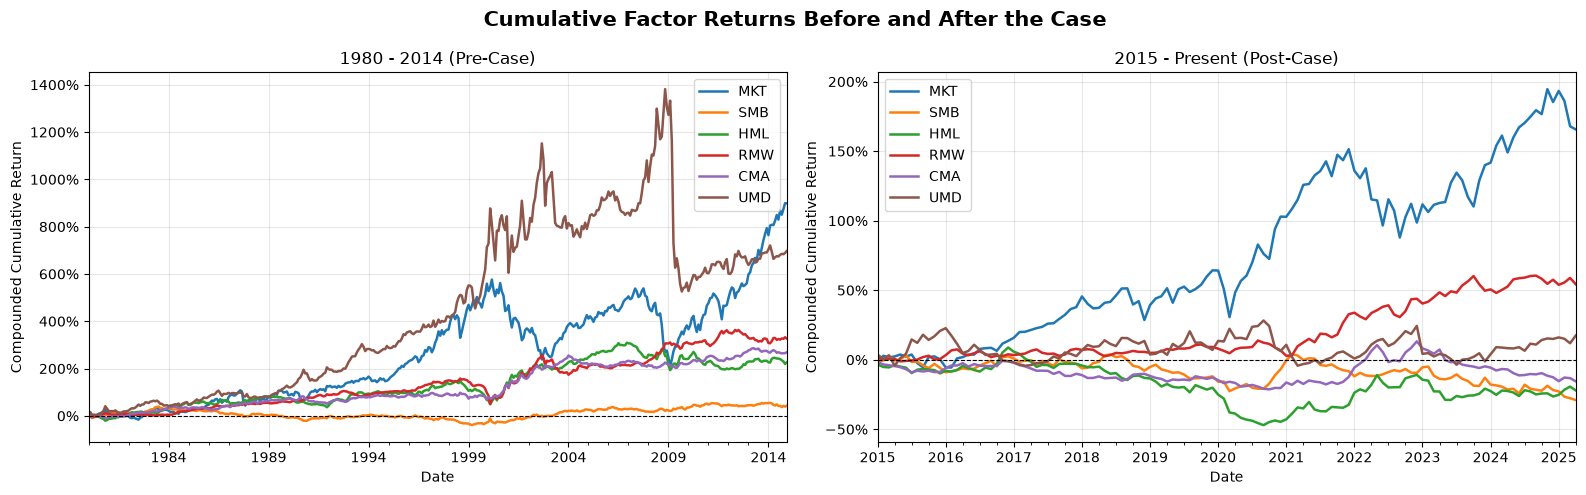

In [7]:
fig, axes = plt.subplots(1, 2, figsize = (16, 5))

for ax, (period, df) in zip(axes, [("1980 - 2014 (Pre-Case)", factors.loc[:"2014"]), ("2015 - Present (Post-Case)", factors.loc["2015":])]):
    cumulative = (1 + df[factor_cols]).cumprod() - 1
    cumulative.plot(ax = ax, linewidth = 1.8)

    ax.set(title = period, xlabel = "Date", ylabel = "Compounded Cumulative Return")
    ax.axhline(0, color = "black", linestyle = "--", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha = 0.3)

fig.suptitle("Cumulative Factor Returns Before and After the Case", fontsize = 15, fontweight = "bold")
plt.tight_layout()
plt.show()

### 3.

Report the correlation matrix across the six factors.

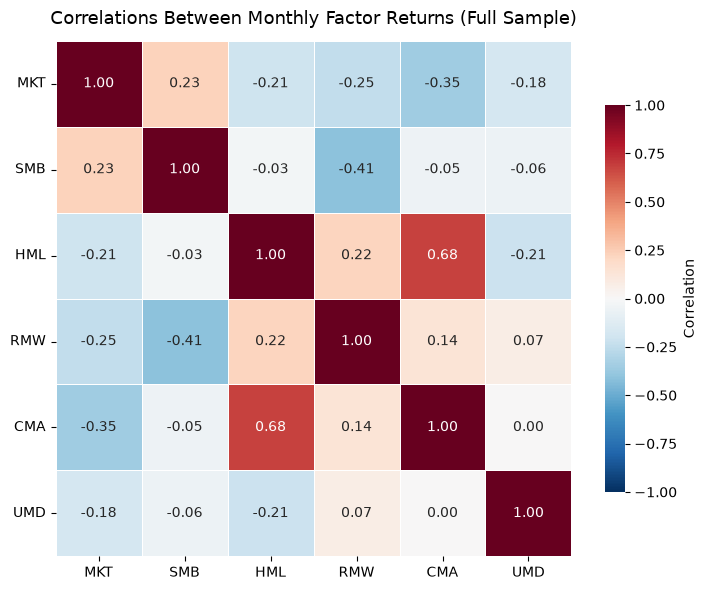

In [8]:
fig, ax = plt.subplots(figsize = (7.5, 6))

sns.heatmap(factors[factor_cols].corr(), annot = True, fmt = ".2f", cmap = "RdBu_r", vmin = -1, vmax = 1, center = 0, square = True, linewidths = 0.5,
            cbar_kws = {"label": "Correlation", "shrink": 0.75}, ax = ax)

ax.set_title("Correlations Between Monthly Factor Returns (Full Sample)", fontsize = 13, pad = 12)
ax.tick_params(axis = "both", labelrotation = 0)

plt.tight_layout()
plt.show()

* Does the construction method succeed in keeping correlations small?

    > Mostly, yes. Of the 15 pairwise correlations, 11 are below 0.25 in absolute value, and several are close to zero (SMB–HML −0.03, CMA–UMD 0.00, SMB–CMA −0.05). Building the factors from 2×3 double sorts on size and each characteristic stops SMB from simply duplicating the value, profitability or investment tilts, and vice versa.
    >
    > The main exceptions are HML–CMA (0.68), SMB–RMW (−0.41) and MKT–CMA (−0.35). The double sort neutralizes size but not the other characteristics, so economically linked characteristics remain correlated. Value firms (high B/M) tend to be low-investment firms, and small firms tend to be less profitable.

* Fama and French say that HML is somewhat redundant in their 5-factor model. Does this seem to be the case?

In [9]:
other_factors = ["MKT", "SMB", "RMW", "CMA", "UMD"]

hml_spanning = pd.concat({"HML on FF5 factors": hw6utils.time_series_test(factors[["HML"]], factors[["MKT", "SMB", "RMW", "CMA"]]),
                          "HML on FF5 factors + UMD": hw6utils.time_series_test(factors[["HML"]], factors[other_factors])}).droplevel(1)
hml_spanning = hml_spanning[["Alpha"] + other_factors + ["R-squared"]]

display(hml_spanning.style.format("{:.4f}").format({"Alpha": "{:.2%}"}))

,Alpha,MKT,SMB,RMW,CMA,UMD,R-squared
HML on FF5 factors,-1.57%,0.042307,0.069154,0.218281,1.024977,nan,0.486855
HML on FF5 factors + UMD,-0.33%,0.012314,0.068478,0.228264,1.000792,-0.156555,0.533731


> Yes. HML's 0.68 correlation with CMA is the highest of any pair. In the spanning regressions above, the other factors explain about half of HML's variation (R² of 0.49 without UMD, 0.53 with it), with a CMA loading of about 1.0. HML's alpha relative to them is negative (−1.57% per year, or −0.33% once UMD is included). Once an investor holds MKT, SMB, RMW and CMA, HML adds little that they do not already have.
>
> The tangency portfolio in the next question confirms this. HML gets a weight of about −2% even though its own Sharpe ratio (0.24) is well above SMB's (0.05).

### 4.

Report the tangency weights for a portfolio of these 6 factors.

In [10]:
reduced_cols = ["MKT", "SMB", "HML", "UMD"]

tangency = pd.DataFrame({"All 6 Factors": hw6utils.tangency_weights(factors[factor_cols]),
                         "MKT, SMB, HML, UMD": hw6utils.tangency_weights(factors[reduced_cols])}).reindex(factor_cols)

tangency_returns = pd.DataFrame({name: factors[tangency.index] @ tangency[name].fillna(0) for name in tangency.columns})

display(tangency.style.format("{:.2%}", na_rep = "-"))
display(hw6utils.performance_summary(tangency_returns).style.format(stats_format))

,All 6 Factors,"MKT, SMB, HML, UMD"
MKT,21.61%,37.15%
SMB,6.67%,-5.37%
HML,-1.97%,36.79%
RMW,30.59%,-
CMA,31.66%,-
UMD,11.44%,31.43%


,Mean,Volatility,Sharpe
All 6 Factors,4.78%,4.00%,1.1944
"MKT, SMB, HML, UMD",6.04%,6.67%,0.9063


* Which factors seem most important? And Least?

    > With all six factors, CMA (31.7%) and RMW (30.6%) get the largest weights, followed by MKT (21.6%) and UMD (11.4%). The least important are HML (−2.0%) and SMB (6.7%). The two "quality" factors from the 2015 five-factor model and the market do most of the work, and the original Fama-French size and value factors contribute little at the margin.

* Are the factors with low mean returns still useful?

    > Yes. CMA's mean (2.77%) is less than a third of MKT's, yet it gets the largest weight. CMA has low volatility (7.25%) and is negatively correlated with MKT (−0.35), so it raises the portfolio Sharpe ratio by hedging market risk. SMB similarly has almost no premium (0.54%) but still gets a positive weight because it hedges RMW (correlation −0.41).
    >
    > HML is the counterexample. Its mean is higher than SMB's, but it gets a negative weight because CMA already provides its exposure. The tangency weight depends on a factor's mean *relative to its covariance with the other factors*, not on its mean alone.

* Re-do the tangency portfolio, but this time only include MKT, SMB, HML, and UMD. Which factors get high/low tangency weights now?

    > Without RMW and CMA, the weights become MKT 37.1%, HML 36.8%, UMD 31.4% and SMB −5.4%. HML goes from the least important factor to one of the most important, because it is now the best available proxy for the investment and profitability premia (it is 0.68 correlated with CMA). SMB still receives a small, negative weight. The tangency Sharpe ratio falls from 1.19 to 0.91 compared with the six-factor portfolio, which shows that RMW and CMA add value beyond what HML captures.

What do you conclude about the importance or unimportance of these styles?

> The market, profitability (RMW), investment (CMA) and momentum (UMD) styles are consistently valuable for building a high-Sharpe portfolio. Momentum gets a meaningful positive weight in both specifications because it is negatively correlated with value and nearly uncorrelated with everything else.
>
> Value matters only when nothing better is available, since its role is largely taken over by CMA. Size is unimportant in every specification. For iShares, this argues for a multifactor product built around quality (profitability/investment) and momentum, with value included as an inexpensive proxy, and with little reason to emphasize size.

***

# 3. Testing Modern LPMs

Consider the following factor models:
* CAPM: MKT
* Fama-French 3F: MKT, SMB, HML
* Fama-French 5F: MKT, SMB, HML, RMW, CMA
* AQR: MKT, HML, RMW, UMD

Our labeling of the last model as the **AQR** is just for concreteness. The firm is well-known for these factors and an unused case study discusses that further.

For instance, for the AQR model is...

$$
\mathbb{E}[\tilde{r}^i] 
= \beta^{i,\mathrm{MKT}} \, \mathbb{E}[\tilde{f}^{\mathrm{MKT}}] 
+ \beta^{i,\mathrm{HML}} \, \mathbb{E}[\tilde{f}^{\mathrm{HML}}] 
+ \beta^{i,\mathrm{RMW}} \, \mathbb{E}[\tilde{f}^{\mathrm{RMW}}] 
+ \beta^{i,\mathrm{UMD}} \, \mathbb{E}[\tilde{f}^{\mathrm{UMD}}]
$$

We will test these models with the time-series regressions. Namely, for each asset i, estimate the following regression to test the AQR model:

$$
\tilde{r}^i_t 
= \alpha^i 
+ \beta^{i,\mathrm{MKT}} \tilde{f}^{\mathrm{MKT}}_t 
+ \beta^{i,\mathrm{HML}} \tilde{f}^{\mathrm{HML}}_t 
+ \beta^{i,\mathrm{RMW}} \tilde{f}^{\mathrm{RMW}}_t 
+ \beta^{i,\mathrm{UMD}} \tilde{f}^{\mathrm{UMD}}_t 
+ \varepsilon_t
$$

### Data

* Monthly excess return data on `n=49` equity portfolios sorted by their industry. Denote these as $\tilde{r}^i$ , for $i = 1, \dots, 49$.

* You do NOT need the risk-free rate data. It is provided only for completeness. The other two tabs are already in terms of excess returns.

### 1.

Test the AQR 4-Factor Model using time-series regressions.

For each regression, report the estimated α and r-squared.

In [11]:
models = {"CAPM": ["MKT"],
          "FF 3-Factor": ["MKT", "SMB", "HML"],
          "FF 5-Factor": ["MKT", "SMB", "HML", "RMW", "CMA"],
          "AQR": ["MKT", "HML", "RMW", "UMD"]}

ts_results = {name: hw6utils.time_series_test(portfolios, factors[cols]) for name, cols in models.items()}

aqr = ts_results["AQR"]

display(aqr[["Alpha", "R-squared"]].style.format({"Alpha": "{:.2%}", "R-squared": "{:.4f}"}))

,Alpha,R-squared
Agric,1.10%,0.3404
Food,0.42%,0.4607
Soda,1.82%,0.3044
Beer,1.11%,0.4207
Smoke,4.30%,0.2657
Toys,-3.46%,0.5092
Fun,4.13%,0.6095
Books,-3.54%,0.6899
Hshld,-1.02%,0.5586
Clths,-2.29%,0.6181


### 2.

Calculate the mean-absolute-error of the estimated alphas.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n|\tilde{\alpha}^i|$$

In [17]:
industry_means = portfolios.mean() * 12

print(f"AQR MAE (annualized):                            {aqr['Alpha'].abs().mean():.2%}")
print(f"Average |mean excess return| of the industries:  {industry_means.abs().mean():.2%}")

AQR MAE (annualized):                            2.46%
Average |mean excess return| of the industries:  8.91%


* If the pricing model worked, should these alpha estimates be large or small? Why?

    > They should be small, zero in population. The model says each asset's expected excess return equals its betas times the factor premia, $\mathbb{E}[\tilde{r}^i] = \boldsymbol{\beta}^{i\prime}\mathbb{E}[\tilde{\boldsymbol{f}}]$. In the time-series regression the alpha is exactly the part of the mean return that the factor betas *don't* explain, so a correct model implies $\alpha^i = 0$ for every asset. Any nonzero sample alphas should then be due only to sampling noise.

* Based on your MAE stat, does this seem to support the pricing model or not?

    > Only partially. The AQR model's MAE is 2.46% per year, which is economically large. It is more than a quarter of the average industry's mean excess return, and individual alphas range from about −5.4% (Real Estate) to +6.9% (Software). With 49 noisy industry portfolios some dispersion is expected, but a typical 2.5% annual pricing error is not consistent with the model fully explaining average returns. As the next question shows, the AQR model also does not beat the CAPM on this test.

### 3.

Test the CAPM, FF 3-Factor Model and the FF 5-Factor Model.

In [13]:
model_summary = pd.DataFrame({"TS MAE (alpha)": {name: res["Alpha"].abs().mean() for name, res in ts_results.items()},
                              "Avg R-squared": {name: res["R-squared"].mean() for name, res in ts_results.items()}})

display(model_summary.style.format({"TS MAE (alpha)": "{:.2%}", "Avg R-squared": "{:.4f}"}))

,TS MAE (alpha),Avg R-squared
CAPM,2.14%,0.5244
FF 3-Factor,2.45%,0.5696
FF 5-Factor,3.15%,0.5939
AQR,2.46%,0.5735


   * Report the MAE statistic for each of these models and compare it with the AQR Model MAE.

        > CAPM 2.14%, FF 3-Factor 2.45%, AQR 2.46%, FF 5-Factor 3.15%. The AQR model is essentially tied with FF3, beats FF5 by about 0.7 percentage points, and is slightly worse than the CAPM.

   * Which model fits best?

        > By the time-series MAE, the CAPM fits best on these 49 industry portfolios. This is surprising, because adding factors does not automatically help in this test. The factor premia are fixed at their sample means, so a factor only reduces alphas if the industries' loadings on it line up with their average returns.
        >
        > Industries are not sorted on size, value, profitability or investment, so their loadings on those factors are often unrelated to their average returns. Multiplying those loadings by large premia (e.g. RMW 4.5%, CMA 2.8%) then creates pricing errors instead of removing them, which is why FF5 does worst. Among the multifactor models, the AQR and FF3 models fit best.

### 4.

Does any particular factor seem especially important or unimportant for pricing? Do you think Fama and French should use the Momentum Factor?

In [14]:
all_factors_mae = hw6utils.time_series_test(portfolios, factors[factor_cols])["Alpha"].abs().mean()

drop_one = pd.Series({factor: hw6utils.time_series_test(portfolios, factors[[f for f in factor_cols if f != factor]])["Alpha"].abs().mean()
                      for factor in factor_cols})

drop_one_table = pd.DataFrame({"MAE without factor": drop_one,
                               "Change vs. all 6 factors": drop_one - all_factors_mae})

print(f"MAE with all 6 factors: {all_factors_mae:.2%}")
display(drop_one_table.style.format("{:.2%}"))

MAE with all 6 factors: 2.87%


,MAE without factor,Change vs. all 6 factors
MKT,11.49%,8.62%
SMB,2.53%,-0.34%
HML,2.92%,0.05%
RMW,2.17%,-0.69%
CMA,2.77%,-0.09%
UMD,3.15%,0.28%


> Starting from a six-factor model and dropping one factor at a time:
>
> * **MKT** is by far the most important. Dropping it raises the MAE from 2.87% to 11.49%.
> * **UMD** and **HML** also help. Dropping UMD raises the MAE by 0.28% and dropping HML by 0.05%.
> * **RMW** and **SMB** hurt pricing on industries. Dropping RMW *lowers* the MAE to 2.17%, and dropping SMB lowers it to 2.53%. CMA is roughly neutral to slightly harmful.
>
> On momentum, yes, these results support including it. Adding UMD to the FF 5-factor model reduces the MAE from 3.15% to 2.87%, and the AQR model, which contains UMD, beats FF5 by about 0.7%. Section 2 also showed that UMD gets a meaningful tangency weight in every specification, because its premium is not spanned by the other factors.
>
> Fama and French's objections are that momentum lacks a clear risk-based explanation and has high turnover. Those may be good reasons to doubt its implementability net of costs, but from a pure pricing perspective, leaving it out makes the model worse.

### 5.

This does not matter for pricing, but report the average (across $n$ estimations) of the time-series regression r-squared statistics.
   * Do this for each of the four models you tested.

In [15]:
display(model_summary[["Avg R-squared"]].style.format("{:.4f}"))

,Avg R-squared
CAPM,0.5244
FF 3-Factor,0.5696
FF 5-Factor,0.5939
AQR,0.5735


   * Do these models lead to high time-series r-squared stats? That is, would these factors be good in a Linear Factor Decomposition of the assets?

        > Not especially. The average R-squared is 0.52 for the CAPM and only rises to 0.57 (FF3, AQR) and 0.59 (FF5) with more factors. The market explains about half of a typical industry's variance, the extra style factors add only 5–7 percentage points, and roughly 40% of industry return variation remains idiosyncratic. That residual is mostly industry-specific risk (e.g. oil prices for Coal, R² ≈ 0.21) that these style factors are not designed to capture.
        >
        > So these factors would be mediocre for a Linear Factor Decomposition or for hedging/replicating industry returns. This is a separate question from pricing: a model can price assets well with low R-squared, or explain variance well while leaving large alphas.

### 6.

Re-test all four models using cross-sectional regressions with an intercept.

In [16]:
premia_rows = {}
cs_mae = {}

for name, cols in models.items():
    premia, residuals = hw6utils.cross_sectional_test(portfolios, ts_results[name][cols])
    premia_no_int, residuals_no_int = hw6utils.cross_sectional_test(portfolios, ts_results[name][cols], intercept = False)

    premia_rows[(name, "Time-series (sample mean)")] = factors[cols].mean() * 12
    premia_rows[(name, "Cross-sectional (with intercept)")] = premia.rename({"const": "Intercept"})
    premia_rows[(name, "Cross-sectional (no intercept)")] = premia_no_int

    cs_mae[name] = {"TS MAE (alpha)": ts_results[name]["Alpha"].abs().mean(),
                    "CS MAE (with intercept)": residuals.abs().mean(),
                    "CS MAE (no intercept)": residuals_no_int.abs().mean()}

premia_table = pd.DataFrame(premia_rows).T[["Intercept"] + factor_cols]
premia_table.index.names = ["Model", "Estimate"]

display(premia_table.style.format("{:.2%}", na_rep = "-"))
display(pd.DataFrame(cs_mae).T.style.format("{:.2%}"))

,TS MAE (alpha),CS MAE (with intercept),CS MAE (no intercept)
CAPM,2.14%,1.55%,2.13%
FF 3-Factor,2.45%,1.20%,1.48%
FF 5-Factor,3.15%,1.19%,1.30%
AQR,2.46%,1.38%,1.72%


* Report the time-series premia of the factors (just their sample averages,) and compare to the cross-sectionally estimated premia of the factors. Do they differ substantially?

    > Yes, very substantially. With an intercept, the cross-sectional market premium is close to zero in every model: 0.21% for the CAPM versus a sample mean of 8.49%, and only about 1.4–3.8% in the multifactor models. The intercept absorbs the equity premium instead, at 6.0–8.7% per year. In other words, the security market line across industries is essentially flat: high-beta industries do not earn proportionally higher average returns, which is the same pattern as Figure 1 of the case.
    >
    > The style premia even change sign. SMB is about −4.5% cross-sectionally versus +0.54% in the time series, HML is −2.0% to −3.3% versus +2.65%, and CMA is −2.4% versus +2.77%. Only RMW keeps a meaningfully positive cross-sectional premium (about 2.1–2.3%), but at half its time-series value. UMD stays positive in the AQR model but shrinks from 6.18% to 0.19%. A large, significant intercept is itself a rejection of the models, since they imply a zero-beta asset should earn zero excess return.
    >
    > When the intercept is set to zero, the market premium must explain the level of average returns, so it moves back toward its sample mean.

* Report the MAE of the cross-sectional regression residuals for each of the four models. How do they compare to the MAE of the time-series alphas?

    > The cross-sectional MAEs (with intercept) are much smaller: CAPM 1.55%, FF3 1.20%, FF5 1.19%, AQR 1.38%, compared with time-series MAEs of 2.14–3.15%. This is mechanical, not evidence that the models work better. The cross-sectional regression *chooses* the premia (plus a free intercept) to minimize the squared pricing errors, whereas the time-series test fixes the premia at the factors' sample means. Once premia are free, adding factors always weakly improves the fit, so the ranking flips: FF5 and FF3 now look best and the CAPM worst.
    >
    > The cost is that the implied premia (a near-zero market premium, negative value and size premia) are far from the factors' actual average returns, so the improvement in fit comes from economically implausible prices of risk.

In Homework 4 (25 size/value portfolios, January 1981 through August 2026), the sample mean market excess return was positive. The cross-sectional CAPM market premium was negative with an intercept and positive when the intercept was fixed at zero.

> The industry portfolios show the same pattern. The time-series market premium is a healthy 8.49%, but with an intercept the cross-sectional CAPM premium collapses to roughly zero (0.21%), while the intercept captures 8.69%. Forcing the intercept to zero restores a positive premium close to the sample mean. With both the size/value portfolios and the industries, the cross-section of average returns is unrelated to market beta, so the "premium" the cross-sectional CAPM assigns to beta depends almost entirely on whether an intercept is allowed.

***